In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/retail_price.csv")
print(f"Total rows: {df.shape[0]}, Total columns: {df.shape[1]}\n")
df.head()

Total rows: 676, Total columns: 30



,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.95,39,161,2,...,89.9,3.9,15.011897,215.000000,4.4,8.760000,45.95,4.0,15.100000,45.90
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.95,39,161,2,...,89.9,3.9,14.769216,209.000000,4.4,21.322000,45.95,4.0,12.933333,45.95
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.95,39,161,2,...,89.9,3.9,13.993833,205.000000,4.4,22.195932,45.95,4.0,14.840000,45.95
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.95,39,161,2,...,89.9,3.9,14.656757,199.509804,4.4,19.412885,45.95,4.0,14.287500,45.95
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.95,39,161,2,...,89.9,3.9,18.776522,163.398710,4.4,24.324687,45.95,4.0,15.100000,45.95


In [4]:
print("Columns")
print(list(df.columns))
print("\nProduct Category Name:")
print(df["product_category_name"].value_counts())

Columns
['product_id', 'product_category_name', 'month_year', 'qty', 'total_price', 'freight_price', 'unit_price', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month', 'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2', 'comp_3', 'ps3', 'fp3', 'lag_price']

Product Category Name:
product_category_name
garden_tools             160
health_beauty            130
watches_gifts            103
computers_accessories     69
bed_bath_table            61
cool_stuff                57
furniture_decor           48
perfumery                 26
consoles_games            22
Name: count, dtype: int64


In [ ]:
print("Missing Values")
missing_summary = pd.DataFrame({
    'Data Type' : df.dtypes,
    'Missing Count':df.isnull().sum(),
    'Missing Pct(%)':(df.isnull().sum()/len(df))*100
})
print(missing_summary[missing_summary["Missing Count"]>0])
df[['qty', 'unit_price', 'total_price', 'comp_1', 'comp_2', 'comp_3', 'freight_price']].describe().T

Missing Values
Empty DataFrame
Columns: [Data Type, Missing Count, Missing Pct(%)]
Index: []


,count,mean,std,min,25%,50%,75%,max
qty,676.0,14.495562,15.443421,1.0,4.000000,10.000000,18.000000,122.00
unit_price,676.0,106.496800,76.182972,19.9,53.900000,89.900000,129.990000,364.00
total_price,676.0,1422.708728,1700.123100,19.9,333.700000,807.890000,1887.322500,12095.00
comp_1,676.0,79.452054,47.933358,19.9,49.910000,69.900000,104.256549,349.90
comp_2,676.0,92.930079,49.481269,19.9,53.900000,89.990000,117.888889,349.90
comp_3,676.0,84.182642,47.745789,19.9,53.785714,59.900000,99.990000,255.61
freight_price,676.0,20.682270,10.081817,0.0,14.761912,17.518472,22.713558,79.76


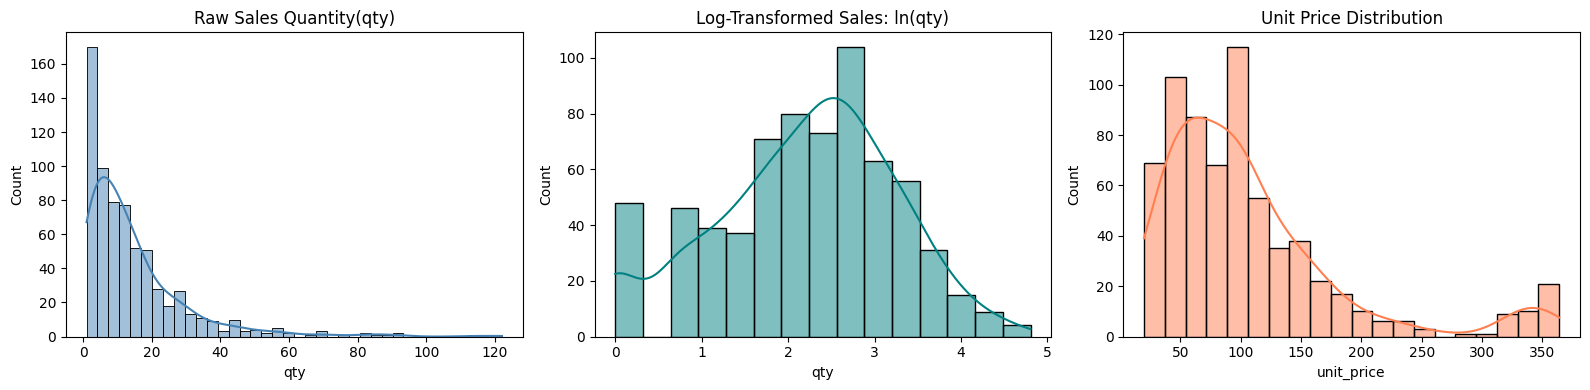

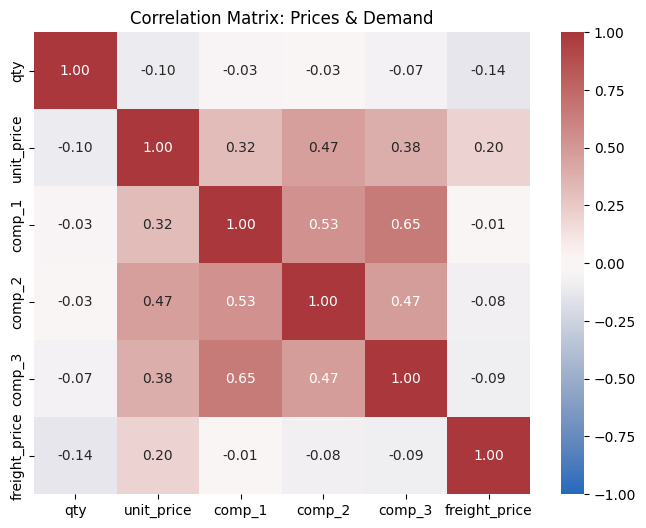

In [8]:
fig,axes = plt.subplots(1,3,figsize=(16,4))
sns.histplot(df['qty'],kde=True,ax=axes[0],color="steelblue")
axes[0].set_title('Raw Sales Quantity(qty)')
sns.histplot(np.log(df['qty']),kde=True,ax=axes[1],color="teal")
axes[1].set_title('Log-Transformed Sales: ln(qty)')
sns.histplot(df['unit_price'],kde=True,ax=axes[2],color="coral")
axes[2].set_title('Unit Price Distribution')

plt.tight_layout()
plt.show()

corr_cols = ['qty', 'unit_price', 'comp_1', 'comp_2', 'comp_3', 'freight_price']
plt.figure(figsize=(8,6))
sns.heatmap(df[corr_cols].corr(),annot=True,cmap='vlag',fmt=".2f",vmin=-1,vmax=+1)
plt.title('Correlation Matrix: Prices & Demand')
plt.show()


Top category by volume:'garden_tools' with 160 records


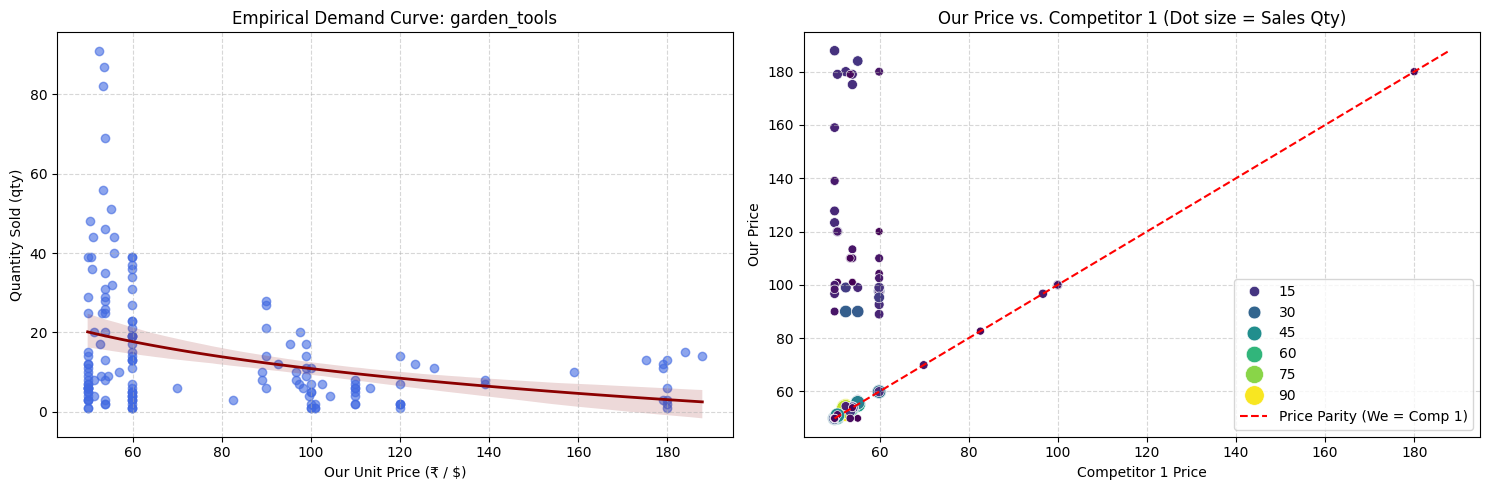

In [10]:
top_category = df.groupby('product_category_name')['qty'].sum().idxmax()
top_df = df[df['product_category_name']==top_category].copy()
print(f"Top category by volume:'{top_category}' with {len(top_df)} records")

fig,axes = plt.subplots(1,2,figsize=(15,5))
sns.regplot(data=top_df,
            x='unit_price',
            y='qty',
            logx=True,
            scatter_kws={'alpha':0.6,'color':'royalblue'},
            line_kws={'color':'darkred','linewidth':2},
            ax=axes[0])
axes[0].set_title(f'Empirical Demand Curve: {top_category}')
axes[0].set_xlabel('Our Unit Price (₹ / $)')
axes[0].set_ylabel('Quantity Sold (qty)')
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.scatterplot(
    data=top_df, 
    x='comp_1', 
    y='unit_price', 
    hue='qty', 
    palette='viridis', 
    size='qty', 
    sizes=(30, 200),
    ax=axes[1])
min_p = min(top_df['comp_1'].min(), top_df['unit_price'].min())
max_p = max(top_df['comp_1'].max(), top_df['unit_price'].max())
axes[1].plot([min_p, max_p], [min_p, max_p], 'r--', label='Price Parity (We = Comp 1)')
axes[1].set_title('Our Price vs. Competitor 1 (Dot size = Sales Qty)')
axes[1].set_xlabel('Competitor 1 Price')
axes[1].set_ylabel('Our Price')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [14]:
df_feat=df.copy()

df_feat['price_diff_comp_1'] = df_feat['unit_price']-df_feat['comp_1']
df_feat['price_diff_comp_2'] = df_feat['unit_price']-df_feat['comp_2']

df_feat['price_ratio_comp_1']=df_feat['unit_price']/df_feat['comp_1']
df_feat['price_ratio_comp_2']=df_feat['unit_price']/df_feat['comp_2']

df_feat['landed_price']=df_feat['unit_price']+df_feat['freight_price']
df_feat['freight_ratio']=df_feat['freight_price']/df_feat['landed_price']

df_feat['date'] = pd.to_datetime(df_feat['month_year'], format='%d-%m-%Y')
df_feat['month'] = df_feat['date'].dt.month
df_feat['year'] = df_feat['date'].dt.year

df_feat['log_qty'] = np.log(df_feat['qty'])
df_feat['log_unit_price'] = np.log(df_feat['unit_price'])
df_feat['log_comp_1']=np.log(df_feat['comp_1'])
print("NEW FEATURES CREATED")
cols_to_preview = [ 'product_id', 'unit_price', 'comp_1', 
    'price_diff_comp_1', 'price_ratio_comp_1', 
    'landed_price','freight_ratio', 'month', 'qty'
]
print(df_feat[cols_to_preview].head(3))



NEW FEATURES CREATED
  product_id  unit_price  comp_1  price_diff_comp_1  price_ratio_comp_1  \
0       bed1       45.95    89.9             -43.95            0.511123   
1       bed1       45.95    89.9             -43.95            0.511123   
2       bed1       45.95    89.9             -43.95            0.511123   

   landed_price  freight_ratio  month  qty  
0     61.050000       0.247338      5    1  
1     58.883333       0.219643      6    3  
2     60.790000       0.244119      7    6  


In [15]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error , mean_absolute_error
from sklearn.linear_model import Ridge 
import lightgbm as lgb

feature_cols = ['unit_price', 'freight_price', 'landed_price',
    'comp_1', 'price_diff_comp_1', 'price_ratio_comp_1',
    'comp_2', 'price_diff_comp_2', 'price_ratio_comp_2',
    'product_score', 'holiday', 'weekday', 'weekend',
    'month', 'customers']

df_model = df_feat.dropna(subset=feature_cols + ['qty']).copy()
df_model = df_model.sort_values(by=['year','month']).reset_index(drop=True)
X = df_model[feature_cols]
y_raw = df_model['qty']
y_log = np.log(df_model['qty'])
split_idx = int(len(df_model)*0.80)
X_train , X_test = X.iloc[:split_idx],X.iloc[split_idx:]
y_train_log , y_test_log = y_log.iloc[:split_idx],y_log.iloc[split_idx:]
y_test_raw = y_raw.iloc[split_idx:]

print(f"Total records: {len(df_model)}")
print(f"Training set:  {len(X_train)} records (Earlier dates)")
print(f"Test set:      {len(X_test)} records (Future unseen dates)")

Total records: 676
Training set:  540 records (Earlier dates)
Test set:      136 records (Future unseen dates)


In [34]:
def calculate_wape(actual , predicted):
    return np.sum(np.abs(actual-predicted)/np.sum(actual)*100)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train,y_train_log)
pred_log_ridge = ridge_model.predict(X_test)
pred_raw_ridge = np.exp(pred_log_ridge)
wape_ridge = calculate_wape(y_test_raw,pred_raw_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test_raw,pred_raw_ridge))

price_sensitive_cols = {
    'unit_price', 'landed_price', 
    'price_diff_comp_1', 'price_ratio_comp_1',
    'price_diff_comp_2', 'price_ratio_comp_2'
}

monotone_constraints = [-1 if col in price_sensitive_cols else 0 for col in feature_cols]

print("--- MONOTONE CONSTRAINTS APPLIED ---")
for col, val in zip(feature_cols, monotone_constraints):
    if val == -1:
        print(f"  • {col:20s}: -1 (Decreasing)")

lgb_model = lgb.LGBMRegressor(
    n_estimators=100,learning_rate=0.05,max_depth=5,monotone_constraints=monotone_constraints,random_state=42,verbosity=-1)
lgb_model.fit(X_train , y_train_log)
pred_log_lgb = lgb_model.predict(X_test)
pred_raw_lgb = np.exp(pred_log_lgb)
wape_lgb = calculate_wape(y_test_raw,pred_raw_lgb)
rmse_lgb = np.sqrt(mean_squared_error(y_test_raw,pred_raw_lgb))

benchmark_df = pd.DataFrame({
    'Model': ['Ridge Regression', 'LightGBM Regressor'],
    'RMSE (Units)': [round(rmse_ridge, 2), round(rmse_lgb, 2)],
    'WAPE (%)': [f"{wape_ridge:.2f}%", f"{wape_lgb:.2f}%"]
})
print("\n--- MODEL PERFORMANCE ON FUTURE UNSEEN TEST DATA ---")
print(benchmark_df)



--- MONOTONE CONSTRAINTS APPLIED ---
  • unit_price          : -1 (Decreasing)
  • landed_price        : -1 (Decreasing)
  • price_diff_comp_1   : -1 (Decreasing)
  • price_ratio_comp_1  : -1 (Decreasing)
  • price_diff_comp_2   : -1 (Decreasing)
  • price_ratio_comp_2  : -1 (Decreasing)

--- MODEL PERFORMANCE ON FUTURE UNSEEN TEST DATA ---
                Model  RMSE (Units) WAPE (%)
0    Ridge Regression         12.17   67.73%
1  LightGBM Regressor         11.31   68.46%


C:\Users\Ashwini\AppData\Local\Temp\ipykernel_3548\2134739367.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance.head(10),x='Importance',y='Feature',palette='Blues_r')


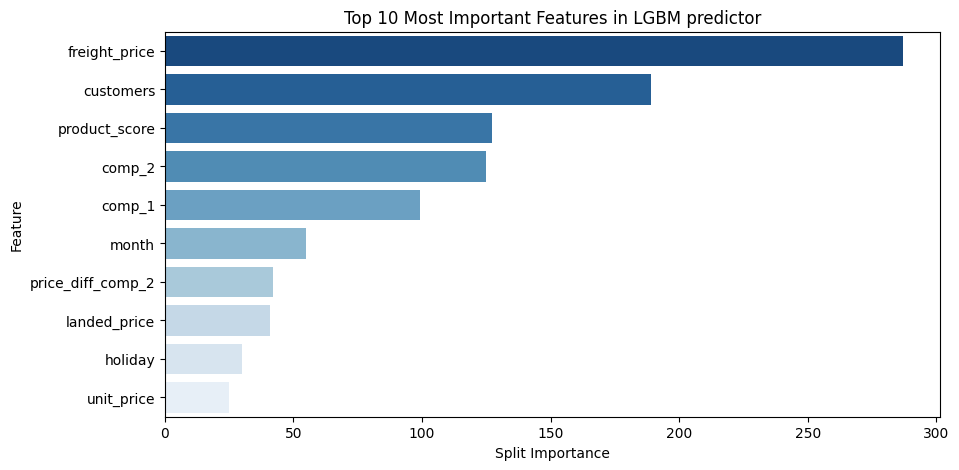


Top 5 Drivers of Demand:
      Feature  Importance
freight_price         287
    customers         189
product_score         127
       comp_2         125
       comp_1          99


In [35]:
feature_importance = pd.DataFrame({
    'Feature':feature_cols,
    'Importance':lgb_model.feature_importances_
}).sort_values('Importance',ascending=False)
plt.figure(figsize=(10,5))
sns.barplot(data=feature_importance.head(10),x='Importance',y='Feature',palette='Blues_r')
plt.title("Top 10 Most Important Features in LGBM predictor")
plt.xlabel('Split Importance')
plt.show()
print("\nTop 5 Drivers of Demand:")
print(feature_importance.head(5).to_string(index=False))


In [36]:
from scipy.optimize import minimize

def get_predicted_demand(candidate_price, base_row, model, feature_columns):
    row = base_row.copy()
    row['unit_price']=candidate_price
    row['landed_price'] = candidate_price + row['freight_price']
    row['price_diff_comp_1'] = candidate_price - row['comp_1']
    row['price_ratio_comp_1'] = candidate_price / max(row['comp_1'], 0.01)
    row['price_diff_comp_2'] = candidate_price - row['comp_2']
    row['price_ratio_comp_2'] = candidate_price / max(row['comp_2'], 0.01)

    X_input = pd.DataFrame([row])[feature_columns]
    pred_log=model.predict(X_input)[0]
    return float(np.exp(pred_log))
def objective_profit_loss(price_array, base_row, unit_cost, model, feature_columns):
    candidate_price = price_array[0]
    expected_units = get_predicted_demand(candidate_price, base_row, model, feature_columns)
    unit_margin = candidate_price - unit_cost
    total_profit = unit_margin * expected_units
    
    return -total_profit

In [37]:
sample_item = X_test.iloc[0].to_dict()
unit_cost = sample_item['unit_price']*0.55
warehouse_stock = 40
current_price = sample_item['unit_price']
comp_price = sample_item['comp_1']
baseline_qty = get_predicted_demand(current_price, sample_item, lgb_model, feature_cols)
baseline_profit = (current_price - unit_cost) * baseline_qty
print(f"--- CURRENT STATUS ---")
print(f"Current Price:       ₹{current_price:.2f}")
print(f"Competitor 1 Price:  ₹{comp_price:.2f}")
print(f"Unit Cost:           ₹{unit_cost:.2f}")
print(f"Current Demand:      {baseline_qty:.1f} units")
print(f"Current Profit:      ₹{baseline_profit:.2f}\n")

price_min = unit_cost + 5.0
price_max = max(current_price * 1.30, comp_price * 1.30)
bounds = [(price_min, price_max)]

stock_constraints = {
    'type':'ineq',
    'fun':lambda p: warehouse_stock - get_predicted_demand(current_price, sample_item, lgb_model, feature_cols)
}
solution = minimize(
    fun = objective_profit_loss, x0=[current_price], args=(sample_item,unit_cost,lgb_model,feature_cols),
    method='SLSQP', bounds=bounds, constraints=[stock_constraints]) 

optimal_price = solution.x[0]
optimal_qty = get_predicted_demand(optimal_price, sample_item, lgb_model, feature_cols)
optimal_profit = -solution.fun
profit_lift = ((optimal_profit - baseline_profit) / baseline_profit) * 100

print(f"--- BRAIN 2 DECISION ---")
print(f"Recommended Price:   ₹{optimal_price:.2f}")
print(f"Projected Demand:    {optimal_qty:.1f} units")
print(f"Projected Profit:    ₹{optimal_profit:.2f}")
print(f"Profit Lift:         {'+' if profit_lift >= 0 else ''}{profit_lift:.2f}%")

if optimal_price > current_price * 1.02:
    print(f"Diagnosis:           UNDERPRICED. Hike price by ₹{optimal_price - current_price:.2f}.")
elif optimal_price < current_price * 0.98:
    print(f"Diagnosis:           OVERPRICED. Discount price by ₹{current_price - optimal_price:.2f}.")
else:
    print("Diagnosis:           OPTIMAL. Keep current price.")

--- CURRENT STATUS ---
Current Price:       ₹110.00
Competitor 1 Price:  ₹53.42
Unit Cost:           ₹60.50
Current Demand:      5.3 units
Current Profit:      ₹263.99

--- BRAIN 2 DECISION ---
Recommended Price:   ₹143.00
Projected Demand:    5.1 units
Projected Profit:    ₹422.36
Profit Lift:         +59.99%
Diagnosis:           UNDERPRICED. Hike price by ₹33.00.


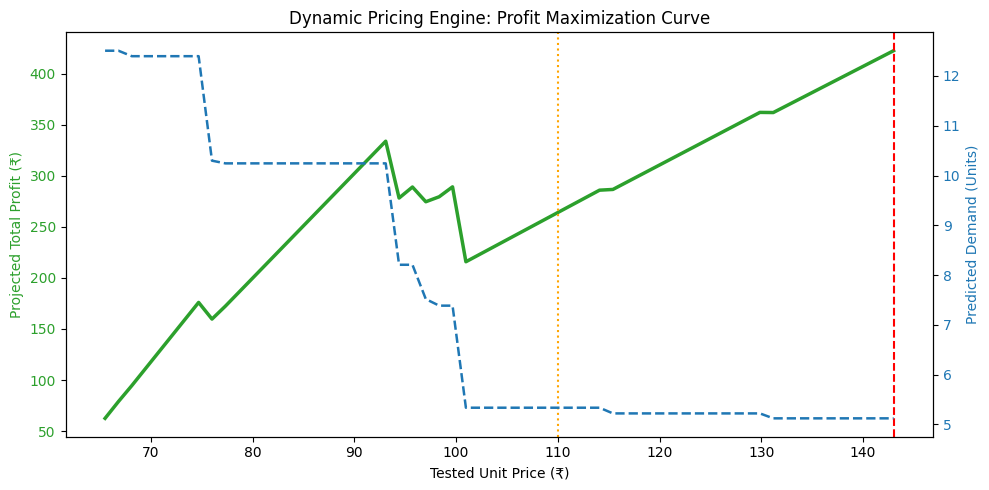

In [38]:
import matplotlib.pyplot as plt

# Scan across the allowed price boundaries
scan_prices = np.linspace(price_min, price_max, 60)
scan_demands = []
scan_profits = []

for p in scan_prices:
    q = get_predicted_demand(p, sample_item, lgb_model, feature_cols)
    prof = (p - unit_cost) * q
    scan_demands.append(q)
    scan_profits.append(prof)

fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Profit Curve (Green)
color = 'tab:green'
ax1.set_xlabel('Tested Unit Price (₹)')
ax1.set_ylabel('Projected Total Profit (₹)', color=color)
ax1.plot(scan_prices, scan_profits, color=color, linewidth=2.5, label='Profit Curve')
ax1.axvline(optimal_price, color='red', linestyle='--', label=f'Recommended: ₹{optimal_price:.2f}')
ax1.axvline(current_price, color='orange', linestyle=':', label=f'Current: ₹{current_price:.2f}')
ax1.tick_params(axis='y', labelcolor=color)

# Plot Demand Curve (Blue) on Secondary Axis
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Predicted Demand (Units)', color=color)
ax2.plot(scan_prices, scan_demands, color=color, linestyle='--', linewidth=1.8, label='Demand Curve')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Dynamic Pricing Engine: Profit Maximization Curve')
fig.tight_layout()
plt.show()

In [39]:
import os
import joblib

# 1. Export artifact directly to the current working directory
artifact = {
    'model': lgb_model,
    'feature_cols': feature_cols
}

joblib.dump(artifact, 'demand_model.joblib')

# 2. Print exact location on disk
print("File successfully saved at:", os.path.abspath('demand_model.joblib'))

File successfully saved at: c:\Users\Ashwini\OneDrive\Desktop\data science project\demand_model.joblib
